# Caption-Image Retrieval demo
Loads the trained model from `demo_bundle.zip` and searches the 1,000 test images. No training.

In [1]:
import os, re, json, zipfile
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    pass

zip_path = next((p for p in ["demo_bundle.zip", "/content/drive/MyDrive/demo_bundle.zip"] if os.path.exists(p)), None)
if zip_path is None:
    from google.colab import files
    zip_path = list(files.upload())[0]
if not os.path.isdir("demo_bundle"):
    zipfile.ZipFile(zip_path).extractall("demo_bundle")
B = "demo_bundle"
dev = "cuda" if torch.cuda.is_available() else "cpu"

Mounted at /content/drive


In [2]:
ck = torch.load(f"{B}/model.pt", map_location="cpu")
itos = json.load(open(f"{B}/vocab.json"))
stoi = {w: i for i, w in enumerate(itos)}
names = json.load(open(f"{B}/images.json"))
L = ck["max_len"]

class Retriever(nn.Module):
    def __init__(self, ck):
        super().__init__()
        D = ck["emb_dim"]
        self.sim, self.bidir, self.is_lstm = ck["sim"], ck["bidir"], ck["rnn"] == "lstm"
        self.emb = nn.Embedding(ck["vocab_size"], ck["glove_dim"], padding_idx=0)
        self.rnn = (nn.LSTM if self.is_lstm else nn.GRU)(ck["glove_dim"], D, batch_first=True, bidirectional=self.bidir)
        self.proj = nn.Linear(2 * D, D) if self.bidir else nn.Identity()
        self.img = nn.Sequential(nn.Dropout(0.0), nn.Linear(ck["feat_dim"], D))

    def post(self, v):
        v = F.normalize(v, dim=-1)
        return v.abs() if self.sim == "order" else v

    def encode_text(self, x, lens):
        packed = nn.utils.rnn.pack_padded_sequence(self.emb(x), lens.cpu(), batch_first=True, enforce_sorted=False)
        _, h = self.rnn(packed)
        if self.is_lstm:
            h = h[0]
        v = torch.cat([h[-2], h[-1]], dim=-1) if self.bidir else h[-1]
        return self.post(self.proj(v))

    def encode_img(self, f):
        return self.post(self.img(f))

    def score(self, c, i):
        if self.sim == "euclid":
            return 2 * c @ i.T - 2
        return -(F.relu(c.unsqueeze(1) - i.unsqueeze(0)) ** 2).sum(-1)

model = Retriever(ck)
model.load_state_dict(ck["state"])
model.to(dev).eval()
bl = torch.load(f"{B}/baseline.pt")
gal = torch.tensor(np.load(f"{B}/gallery_feats.npy")).to(dev)
with torch.no_grad():
    gal_emb = model.encode_img(gal)
print("loaded:", ck["name"], "|", len(names), "images")

loaded: GRU + GloVe (order emb) | 1000 images


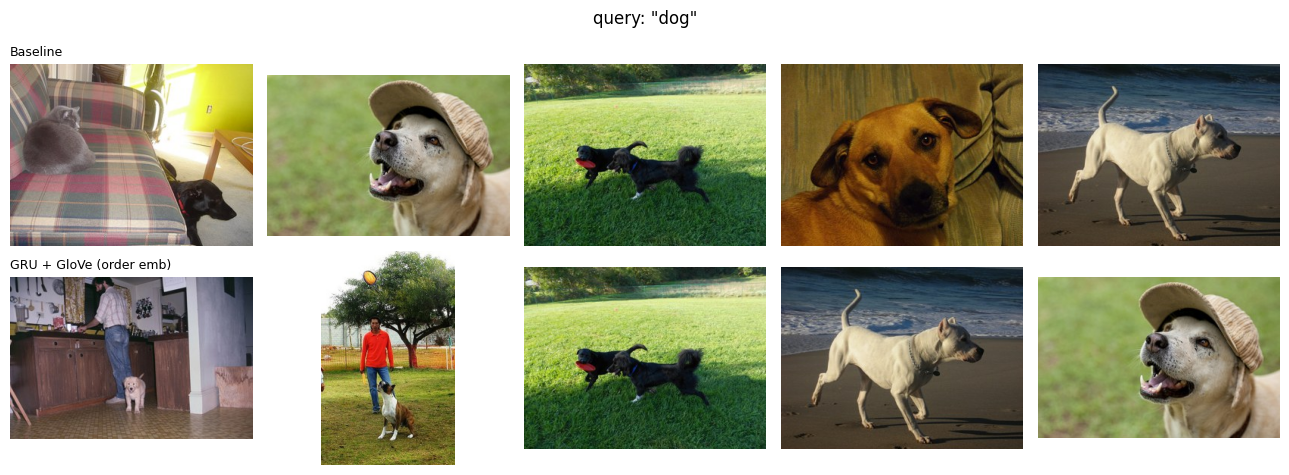

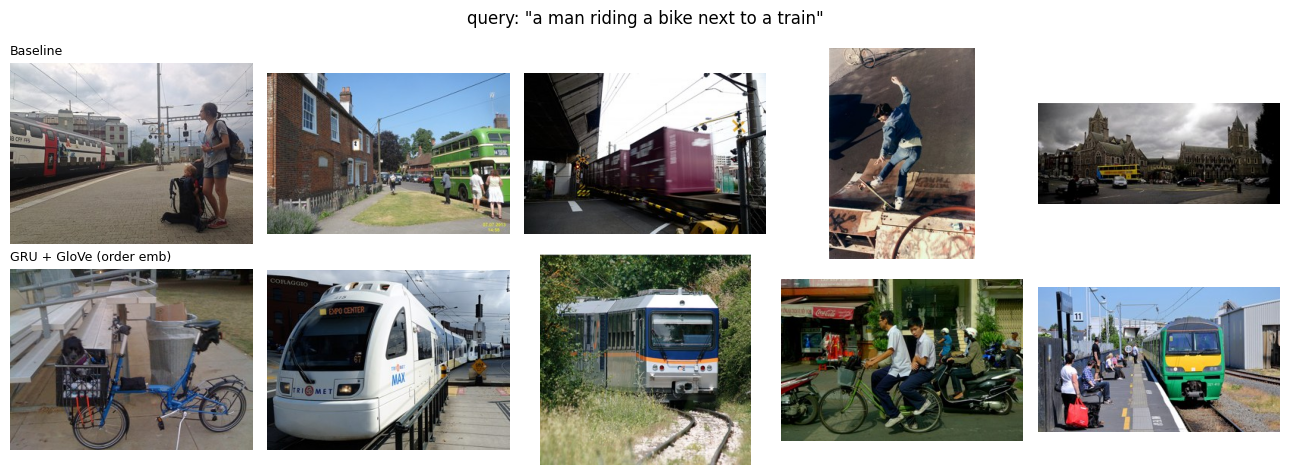

In [3]:
def tokenize(s):
    return re.findall(r"[a-z0-9]+", s.lower())

@torch.no_grad()
def search(q, k=5):
    toks = [stoi.get(w, 1) for w in tokenize(q)][:L] or [1]
    x = torch.zeros(1, L, dtype=torch.long); x[0, :len(toks)] = torch.tensor(toks)
    x, ln = x.to(dev), torch.tensor([len(toks)])
    top = model.score(model.encode_text(x, ln), gal_emb)[0].topk(k).indices.tolist()
    g = bl["G"][x.cpu()[0, :len(toks)]].mean(0, keepdim=True)
    pred = (g - bl["xm"]) @ bl["W"] + bl["ym"]
    base = (-torch.cdist(pred, gal.cpu()) ** 2)[0].topk(k).indices.tolist()
    return {"Baseline": base, ck["name"]: top}

def show(q, k=5):
    res = search(q, k)
    fig, axes = plt.subplots(len(res), k, figsize=(2.6 * k, 2.4 * len(res)))
    for r, (name, idx) in enumerate(res.items()):
        for c, j in enumerate(idx):
            axes[r][c].imshow(Image.open(f"{B}/images/{names[j]}")); axes[r][c].axis("off")
            if c == 0:
                axes[r][c].set_title(name, fontsize=9, loc="left")
    fig.suptitle(f'query: "{q}"')
    plt.tight_layout(); plt.show()

show("dog")
show("a man riding a bike next to a train")

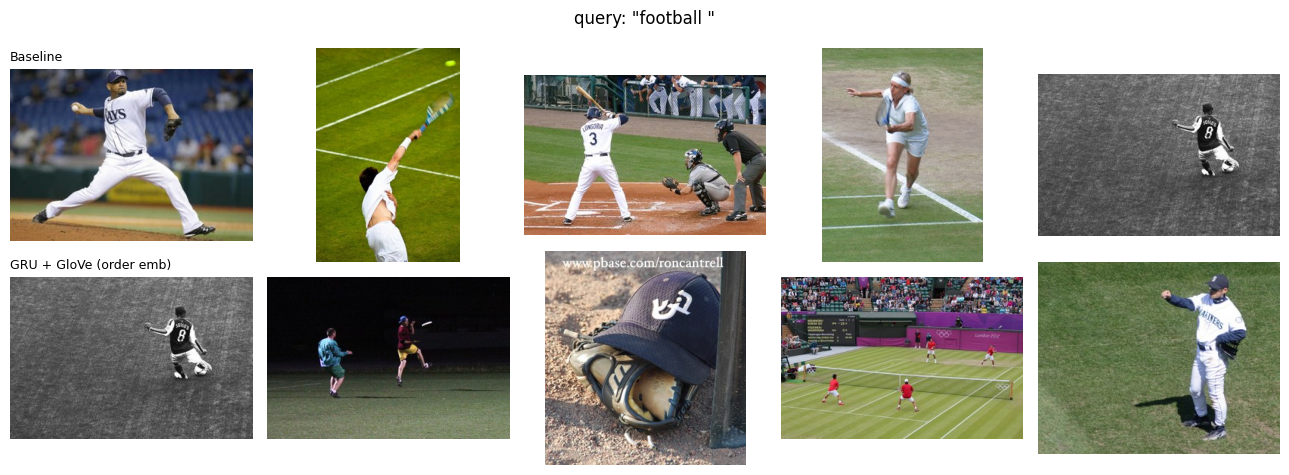

In [7]:
query = "football "  #@param {type:"string"}
show(query)

In [5]:
import pandas as pd
display(pd.DataFrame(json.load(open(f"{B}/results.json"))).set_index("Method"))

,R@1,R@5,R@10,MedR,MeanR
Method,,,,,
Baseline (ridge on mean GloVe),4.4,13.7,20.6,82.0,190.1
GRU (random init),30.3,64.6,79.5,3.0,11.4
GRU + GloVe,29.5,65.1,80.4,3.0,10.2
LSTM + GloVe,31.1,66.2,80.3,3.0,10.2
GRU + GloVe (order emb),32.3,67.1,80.7,3.0,9.7
